# Latent TTA — die drei Experimente aus dem Professoren-Feedback

Ein Notebook für alle drei Läufe. Jeder Lauf ist ein eigener Schalter auf derselben App
(`apps/eval_latent_tta.py`) und schreibt in ein eigenes Verzeichnis unter `results/`:

| # | Frage | Schalter | Skript | Ergebnisse |
|---|---|---|---|---|
| 0 | Referenz: Ascent auf dem *erwarteten* Dice | `objective=mu`, `placement=post` | `eval_latent_tta.sh` | `results/latent_tta_baseline/` |
| 1 | Was könnte ein bestmögliches Orakel erreichen? | `objective=oracle-dice` | `exp1_oracle_dice.sh` | `results/latent_tta_oracle/` |
| 2 | Was passiert bei Pre- statt Post-Norm? | `placement=pre` | `exp2_prenorm_adapter.sh` | `results/latent_tta_prenorm/` |
| 3a | Wie sehen die Kappa-Confidence-Bounds aktuell aus? | — (keine Adaption) | `exp3_kappa_bounds.sh` | `results/kappa_bounds/` |
| 3b | Unsicherheit simultan absenken | `kappa_weight>0` | `exp3_kappa_descent.sh` | `results/latent_tta_kappa_*/` |

## Harter Dice, weicher Dice — warum das Orakel einen Soft-Dice braucht

Der berichtete („harte") Dice wird aus der **diskreten** Segmentierung berechnet:
erst `argmax` bzw. `logits > 0`, dann Overlap zählen. Diese Abbildung ist stückweise
konstant: eine kleine Änderung der Logits verschiebt kein einziges Pixel über seine
Entscheidungsschwelle, die Vorhersagemaske bleibt identisch, der Dice-Wert ändert sich
also **überhaupt nicht** → Gradient exakt 0. Und genau an der Schwelle (Logit = 0) springt
der Wert um einen ganzen Pixel → dort ist er nicht differenzierbar. Fast überall 0, an den
Sprungstellen undefiniert: als Ziel für Gradient Ascent unbrauchbar.

Der **Soft-Dice** ersetzt die harte 0/1-Maske durch die vorhergesagte
Wahrscheinlichkeit $p_c = \sigma(\text{logit})$ bzw. $\text{softmax}$:

$$\text{softDice}_c = \frac{2\sum_i p_{c,i}\, t_{c,i} + \varepsilon}{\sum_i p_{c,i} + \sum_i t_{c,i} + \varepsilon}$$

Ein Pixel, das mit $p=0.6$ als Vordergrund gilt, zählt jetzt mit 0.6 statt mit 1. Damit
ist der Wert glatt in den Logits: Sicherer-Werden an einer richtigen Stelle erhöht ihn
kontinuierlich, und es gibt einen Gradienten, dem man folgen kann. Für sichere
Vorhersagen ($p \to 0/1$) fällt er mit dem harten Dice zusammen — er ist eine
differenzierbare Relaxierung desselben Maßes, kein anderes Maß.

Implementierung: `soft_dice_from_logits` in `src/losses.py` (gleiche Empty-Empty-Konvention
`ignore_empty=False` wie die berichtete Metrik). **Optimiert** wird im Orakel-Lauf der
Soft-Dice, **berichtet** wird überall der harte Dice — die Tabellen unten sind also
vergleichbar mit allen bisherigen Zahlen.

In [1]:
import os, sys, glob, pickle as pkl
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt

ROOT = Path('../../').resolve()          # repo root
RESULTS = ROOT / 'results'
sys.path.append(str(ROOT / 'src'))

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3,
                     'axes.spines.top': False, 'axes.spines.right': False})

# Which checkpoint to look at (substring). All experiments must use the same one.
CKPT_FILTER = 'cleanHalf_0'
SPLIT_FILTER = ''      # '' = whatever is in the directory, e.g. 'threet-to-onepointfivet'
print(RESULTS)

/root/workspace/repos/isbi26-implementation/results


## Laden

In [2]:
def load_runs(result_dir, filename='latent_tta.pkl', ckpt_filter=CKPT_FILTER,
              split_filter=SPLIT_FILTER):
    """All pickles of one experiment directory -> {ckpt_name: payload}."""
    base = RESULTS / result_dir
    out = {}
    for path in sorted(base.glob(f'*/{filename}')):
        name = path.parent.name
        if ckpt_filter and ckpt_filter not in name:
            continue
        if split_filter and split_filter not in name:
            continue
        with open(path, 'rb') as f:
            out[name] = pkl.load(f)
    return out


def first_run(result_dir, filename='latent_tta.pkl'):
    """Single payload of one experiment (the first matching checkpoint)."""
    runs = load_runs(result_dir, filename)
    if not runs:
        print(f'[missing] no results in results/{result_dir} '
              f'(filter={CKPT_FILTER!r}) -- run the corresponding script first')
        return None
    name = sorted(runs)[0]
    if len(runs) > 1:
        print(f'[info] {len(runs)} checkpoints in {result_dir}, using {name}')
    return runs[name]


EXPERIMENTS = {
    'baseline (mu-hat)':  'latent_tta_baseline',
    'oracle (real Dice)': 'latent_tta_oracle',
    'pre-norm':           'latent_tta_prenorm',
    'kappa descent':      'latent_tta_kappa_sigma_w0.1',
}

runs = {label: first_run(d) for label, d in EXPERIMENTS.items()}
runs = {k: v for k, v in runs.items() if v is not None}

for label, payload in runs.items():
    tta = payload['metadata']['tta']
    print(f"{label:22s} objective={tta.get('objective','mu'):11s} "
          f"placement={tta.get('placement','post'):5s} "
          f"kappa_w={tta.get('kappa_weight',0.0)}  "
          f"steps={tta['max_steps']}  sites={tta['adapt_sites']}  "
          f"domains={list(payload['evaluation'])}")

baseline (mu-hat)      objective=mu          placement=post  kappa_w=0.0  steps=100  sites=[0, 17]  domains=['threet-to-onepointfivet_val', 'threet-to-onepointfivet_test']
oracle (real Dice)     objective=oracle-dice placement=post  kappa_w=0.0  steps=100  sites=[0, 17]  domains=['threet-to-onepointfivet_val', 'threet-to-onepointfivet_test']
pre-norm               objective=mu          placement=pre   kappa_w=0.0  steps=100  sites=[0, 17]  domains=['threet-to-onepointfivet_val', 'threet-to-onepointfivet_test']
kappa descent          objective=mu          placement=post  kappa_w=0.1  steps=100  sites=[0, 17]  domains=['threet-to-onepointfivet_val', 'threet-to-onepointfivet_test']


## Übersicht: alle Läufe, alle Domänen

`Dice vor/nach` ist der **harte** Dice. `logit drift` ist das mittlere $|\text{logits} -
\text{logits}_0|$ am Ende der Adaption — die Diagnose für Experiment 2: bleibt sie ~0,
hat sich die Segmentierung trotz steigendem mu-hat *nicht bewegt*.
`oracle stop` ist der bestmögliche Stoppzeitpunkt pro Bild (braucht Labels, nur Analyse).

In [3]:
def summarize(label, payload):
    rows = []
    for domain, r in payload['evaluation'].items():
        d0 = r['dice_before'].mean().item()
        d1 = r['dice_after'].mean().item()
        rows.append(dict(
            run=label, domain=domain, n=r['dice_before'].numel(),
            dice_before=d0, dice_after=d1, delta_dice=d1 - d0,
            mu_before=r['mu_before'].mean().item(),
            mu_after=r['mu_after'].mean().item(),
            kappa_before=r['kappa_before'].mean().item(),
            kappa_after=r['kappa_after'].mean().item(),
            sigma_before=r['sigma_before'].mean().item(),
            sigma_after=r['sigma_after'].mean().item(),
            logit_drift=r['logit_drift'].mean().item(),
            improved=(r['dice_after'] > r['dice_before']).float().mean().item(),
            oracle_stop=r['best_dice'].mean().item(),
        ))
    return rows

try:
    import pandas as pd
    table = pd.DataFrame([row for l, p in runs.items() for row in summarize(l, p)])
    display(table.style.format({
        'dice_before': '{:.4f}', 'dice_after': '{:.4f}', 'delta_dice': '{:+.4f}',
        'mu_before': '{:.4f}', 'mu_after': '{:.4f}',
        'kappa_before': '{:.1f}', 'kappa_after': '{:.1f}',
        'sigma_before': '{:.4f}', 'sigma_after': '{:.4f}',
        'logit_drift': '{:.2e}', 'improved': '{:.1%}', 'oracle_stop': '{:.4f}',
    }).hide(axis='index'))
except ImportError:
    for l, p in runs.items():
        for row in summarize(l, p):
            print(row)

run,domain,n,dice_before,dice_after,delta_dice,mu_before,mu_after,kappa_before,kappa_after,sigma_before,sigma_after,logit_drift,improved,oracle_stop
baseline (mu-hat),threet-to-onepointfivet_val,103,0.8605,0.8350,-0.0254,0.8649,0.9202,56.6,96.4,0.0621,0.0332,1.78e+00,27.2%,0.8751
baseline (mu-hat),threet-to-onepointfivet_test,481,0.6774,0.7528,+0.0754,0.6691,0.8425,26.1,60.7,0.1114,0.0615,2.42e+00,59.5%,0.7851
oracle (real Dice),threet-to-onepointfivet_val,103,0.8605,0.9667,+0.1063,0.8649,0.8731,56.6,52.2,0.0621,0.0588,1.63e+00,100.0%,0.9668
oracle (real Dice),threet-to-onepointfivet_test,481,0.6774,0.9375,+0.2601,0.6691,0.7927,26.1,30.9,0.1114,0.0976,1.73e+00,100.0%,0.9376
pre-norm,threet-to-onepointfivet_val,103,0.8605,0.8604,-0.0000,0.8649,0.9836,56.6,1011.3,0.0621,0.0060,1.11e-03,16.5%,0.8605
pre-norm,threet-to-onepointfivet_test,481,0.6774,0.6774,+0.0000,0.6691,0.8927,26.1,652.8,0.1114,0.0340,5.83e-04,12.3%,0.6775
kappa descent,threet-to-onepointfivet_val,103,0.8605,0.8347,-0.0257,0.8649,0.9202,56.6,97.3,0.0621,0.0329,1.76e+00,26.2%,0.8756
kappa descent,threet-to-onepointfivet_test,481,0.6774,0.7524,+0.0750,0.6691,0.8413,26.1,61.1,0.1114,0.0609,2.42e+00,60.5%,0.7840


# Experiment 1 — Orakel: obere Schranke

Ersetzt im Gradient Ascent den *erwarteten* Dice (mu-hat) durch den *realen* (Soft-)Dice.
In der Praxis nicht anwendbar, weil es die Ground-Truth-Labels benutzt. Zwei Lesarten:

* **Obere Schranke** — was diese Adaptions-Familie (per-Kanal-Affine an zwei Swivels)
  überhaupt hergäbe, wenn der Qualitätsschätzer perfekt wäre.
* **Preis der Korrelation** — der Abstand zwischen Orakel- und mu-hat-Kurve ist genau der
  Anteil der Verbesserung, der an der imperfekten Korrelation zwischen erwartetem und
  realem Dice hängt.

In [4]:
def step_curve(payload, domain, key='dice_per_step'):
    """Mittelwert über Bilder pro Schritt, NaN-tolerant (Early-Stopping-Padding)."""
    m = payload['evaluation'][domain][key]
    if m is None or (hasattr(m, 'numel') and m.numel() == 0):
        return None
    return torch.nanmean(m.float(), dim=0).numpy()


def domains_of(payload):
    return list(payload['evaluation'])


ref = runs.get('baseline (mu-hat)') or next(iter(runs.values()))
DOMAINS = domains_of(ref)
TEST_DOMAIN = [d for d in DOMAINS if d.endswith('_test')] or DOMAINS
TEST_DOMAIN = TEST_DOMAIN[0]
print('Domänen:', DOMAINS, '| Fokus:', TEST_DOMAIN)

Domänen: ['threet-to-onepointfivet_val', 'threet-to-onepointfivet_test'] | Fokus: threet-to-onepointfivet_test


### Die drei Kurven im Plot unten

Es sind **zwei getrennte Läufe** über dieselben Bilder, und aus dem ersten werden **zwei**
Größen gezeigt. Die y-Achse ist in allen Fällen eine Dice-Skala von 0 bis 1 — mu-hat ist ja
eine Schätzung genau dieses Dice und damit direkt vergleichbar.

| Kurve | Lauf | Was das Objective maximiert | Was geplottet ist |
|---|---|---|---|
| blau | A (Baseline) | mu-hat, die *Schätzung* des Dice — label-frei, einsetzbar | der mit Labels **nachgemessene echte** Dice |
| orange | B (Orakel) | den *echten* (Soft-)Dice — braucht Labels, nicht einsetzbar | derselbe nachgemessene echte Dice |
| grau gestrichelt | A (Baseline) | — | **mu-hat selbst**, also die Zielgröße, die Lauf A hochtreibt |

Damit lassen sich zwei Dinge auf einen Blick ablesen:

* **blau vs. orange** = der Preis der imperfekten Korrelation. Was verliert man dadurch,
  dass man dem geschätzten statt dem echten Dice folgt?
* **grau vs. blau** = die Selbsttäuschung des Schätzers. Grau steigt monoton weiter (der
  Optimierer „glaubt", es werde immer besser), während blau ab Schritt ~55 abknickt und
  fällt. Der Head merkt also nicht, wann er anfängt, die Segmentierung kaputtzumachen —
  genau deshalb trägt mu-hat auch keine Stopp-Information.

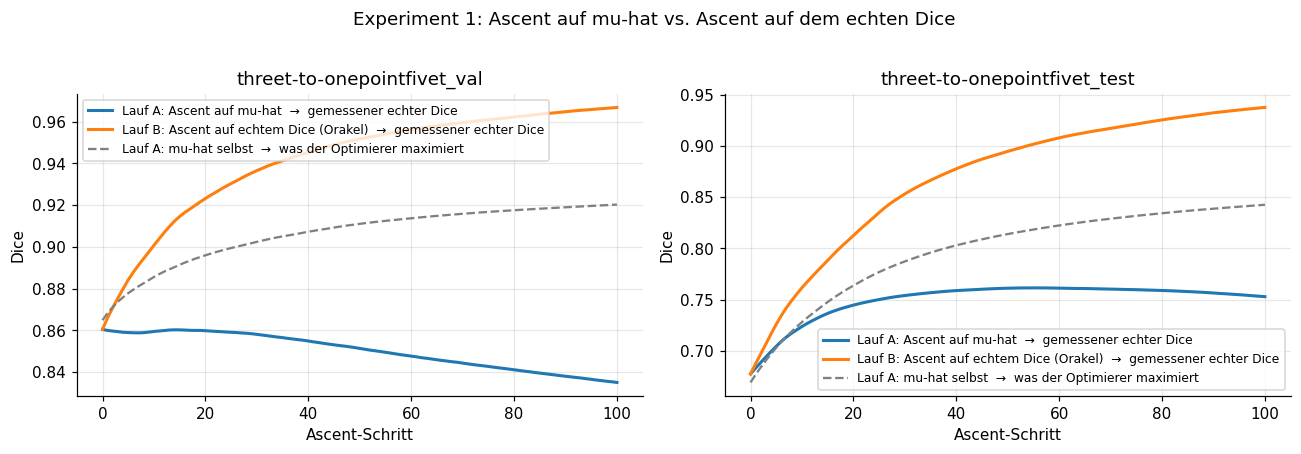

In [5]:
pair = {k: runs[k] for k in ('baseline (mu-hat)', 'oracle (real Dice)') if k in runs}

if len(pair) == 2:
    fig, axes = plt.subplots(1, len(DOMAINS), figsize=(6 * len(DOMAINS), 4), squeeze=False)
    for ax, domain in zip(axes[0], DOMAINS):
        LEGEND = {
            'baseline (mu-hat)':  'Lauf A: Ascent auf mu-hat  →  gemessener echter Dice',
            'oracle (real Dice)': 'Lauf B: Ascent auf echtem Dice (Orakel)  →  gemessener echter Dice',
        }
        for label, payload in pair.items():
            dice = step_curve(payload, domain, 'dice_per_step')
            ax.plot(dice, label=LEGEND[label], lw=2)
        mu = step_curve(pair['baseline (mu-hat)'], domain, 'mu_per_step')
        ax.plot(mu, '--', color='grey',
                label='Lauf A: mu-hat selbst  →  was der Optimierer maximiert')
        ax.set_title(domain)
        ax.set_xlabel('Ascent-Schritt'); ax.set_ylabel('Dice')
        ax.legend(fontsize=8)
    fig.suptitle('Experiment 1: Ascent auf mu-hat vs. Ascent auf dem echten Dice', y=1.02)
    plt.tight_layout(); plt.show()
else:
    print('Baseline und/oder Orakel-Lauf fehlt.')

In [6]:
if len(pair) == 2:
    print(f'{"Domäne":32s} {"Baseline":>18s} {"Orakel":>18s} {"Anteil erreicht":>16s}')
    for domain in DOMAINS:
        b = pair['baseline (mu-hat)']['evaluation'][domain]
        o = pair['oracle (real Dice)']['evaluation'][domain]
        db = b['dice_after'].mean().item() - b['dice_before'].mean().item()
        do = o['dice_after'].mean().item() - o['dice_before'].mean().item()
        frac = db / do if do != 0 else float('nan')
        print(f'{domain:32s} {db:+18.4f} {do:+18.4f} {frac:15.1%}')
    print('\n"Anteil erreicht" = wie viel der label-freie mu-hat-Ascent von dem holt,')
    print('was mit perfektem Qualitätsschätzer möglich wäre.')

Domäne                                     Baseline             Orakel  Anteil erreicht
threet-to-onepointfivet_val                 -0.0254            +0.1063          -23.9%
threet-to-onepointfivet_test                +0.0754            +0.2601           29.0%

"Anteil erreicht" = wie viel der label-freie mu-hat-Ascent von dem holt,
was mit perfektem Qualitätsschätzer möglich wäre.


### Woran hängt es? Korrelation zwischen erwartetem und realem Dice

Der mu-hat-Ascent kann nur so gut sein, wie mu-hat den echten Dice *nachbildet*. Links die
Korrelation im Ausgangszustand (Schritt 0), rechts der per-Bild-Vergleich der erreichten
Verbesserung.

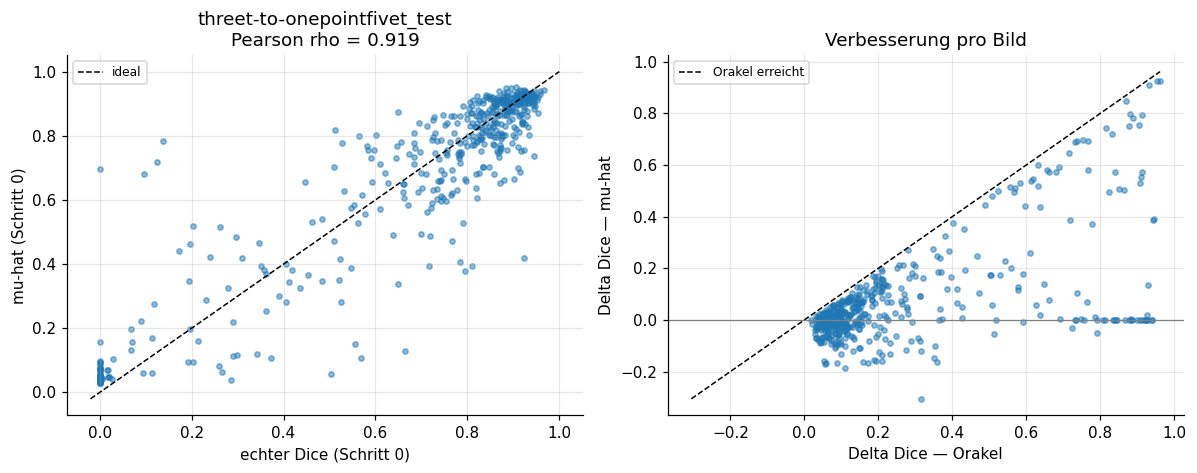

In [7]:
if len(pair) == 2:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))

    b = pair['baseline (mu-hat)']['evaluation'][TEST_DOMAIN]
    o = pair['oracle (real Dice)']['evaluation'][TEST_DOMAIN]

    mu0, d0 = b['mu_before'].numpy(), b['dice_before'].numpy()
    rho = np.corrcoef(mu0, d0)[0, 1]
    axes[0].scatter(d0, mu0, s=12, alpha=.5)
    lims = [min(d0.min(), mu0.min()) - .02, 1.0]
    axes[0].plot(lims, lims, 'k--', lw=1, label='ideal')
    axes[0].set_xlabel('echter Dice (Schritt 0)'); axes[0].set_ylabel('mu-hat (Schritt 0)')
    axes[0].set_title(f'{TEST_DOMAIN}\nPearson rho = {rho:.3f}')
    axes[0].legend(fontsize=8)

    gain_b = (b['dice_after'] - b['dice_before']).numpy()
    gain_o = (o['dice_after'] - o['dice_before']).numpy()
    axes[1].scatter(gain_o, gain_b, s=12, alpha=.5)
    lo = min(gain_b.min(), gain_o.min()); hi = max(gain_b.max(), gain_o.max())
    axes[1].plot([lo, hi], [lo, hi], 'k--', lw=1, label='Orakel erreicht')
    axes[1].axhline(0, color='grey', lw=.8)
    axes[1].set_xlabel('Delta Dice — Orakel'); axes[1].set_ylabel('Delta Dice — mu-hat')
    axes[1].set_title('Verbesserung pro Bild')
    axes[1].legend(fontsize=8)
    plt.tight_layout(); plt.show()

# Experiment 2 — Latent-Adapter von Post-Norm nach Pre-Norm

Die Swivels sind `adn.N`-Module, also `InstanceNorm2d(affine=False)`. Eine per-Kanal-Affine
**vor** dieser Norm wird von ihr wieder aufgehoben:

$$\mathrm{IN}(\gamma_c x + \beta_c) = \mathrm{IN}(x) \qquad (\text{bis auf } \varepsilon \text{ und } \operatorname{sign}(\gamma))$$

Damit das Experiment überhaupt etwas misst, wird der Pre-Hook mit `prepend=True`
registriert: er läuft **vor** dem Recording-Hook des Score-Predictors, der QC-Head sieht
also die adaptierten Features. Der Segmentierungspfad sieht sie nicht.

Erwartete Signatur: **mu-hat steigt, die Logits bewegen sich nicht.** Genau das misst
`logit_drift`.

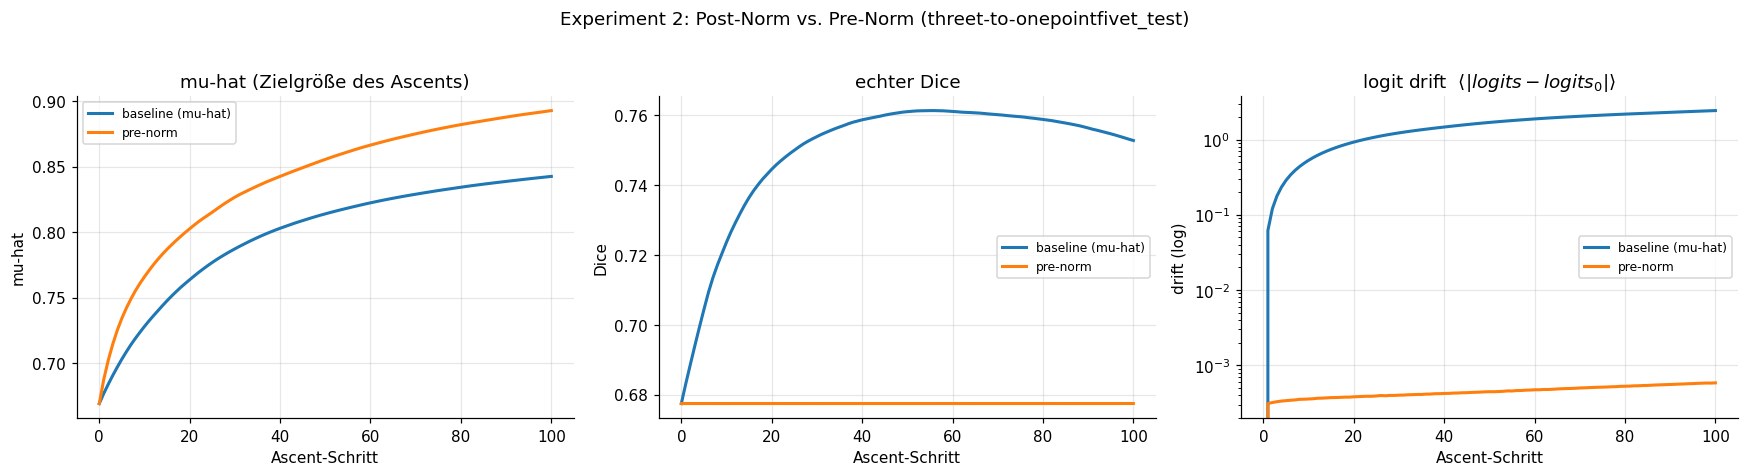

baseline (mu-hat)    mu 0.6691 -> 0.8425 | Dice 0.6774 -> 0.7528 (+0.0754) | logit drift 2.42e+00
pre-norm             mu 0.6691 -> 0.8927 | Dice 0.6774 -> 0.6774 (+0.0000) | logit drift 5.83e-04


In [8]:
comp = {k: runs[k] for k in ('baseline (mu-hat)', 'pre-norm') if k in runs}

if len(comp) == 2:
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
    for label, payload in comp.items():
        axes[0].plot(step_curve(payload, TEST_DOMAIN, 'mu_per_step'), lw=2, label=label)
        axes[1].plot(step_curve(payload, TEST_DOMAIN, 'dice_per_step'), lw=2, label=label)
        axes[2].plot(step_curve(payload, TEST_DOMAIN, 'logit_drift_per_step'), lw=2, label=label)
    axes[0].set_title('mu-hat (Zielgröße des Ascents)'); axes[0].set_ylabel('mu-hat')
    axes[1].set_title('echter Dice'); axes[1].set_ylabel('Dice')
    axes[2].set_title(r'logit drift  $\langle|logits - logits_0|\rangle$')
    axes[2].set_yscale('log'); axes[2].set_ylabel('drift (log)')
    for ax in axes:
        ax.set_xlabel('Ascent-Schritt'); ax.legend(fontsize=8)
    fig.suptitle(f'Experiment 2: Post-Norm vs. Pre-Norm ({TEST_DOMAIN})', y=1.02)
    plt.tight_layout(); plt.show()

    for label, payload in comp.items():
        r = payload['evaluation'][TEST_DOMAIN]
        d0 = r['dice_before'].mean().item(); d1 = r['dice_after'].mean().item()
        print(f"{label:20s} mu {r['mu_before'].mean():.4f} -> {r['mu_after'].mean():.4f} | "
              f"Dice {d0:.4f} -> {d1:.4f} ({d1-d0:+.4f}) | "
              f"logit drift {r['logit_drift'].mean():.2e}")
else:
    print('Baseline und/oder Pre-Norm-Lauf fehlt.')

# Experiment 3 — Kappa

### 3a: Wie sehen die Confidence-Bounds der *aktuellen* Vorhersagen aus?

Der Head sagt nicht nur einen Punkt vorher, sondern eine ganze
$\mathrm{Beta}(\mu\kappa, (1-\mu)\kappa)$-Verteilung über den Score. Daraus lässt sich ein
gleichseitiges Credible-Intervall bilden, dessen **empirische Überdeckung** des echten Dice
man messen kann:

* Überdeckung deutlich **unter** dem nominalen Niveau → der Head ist **überkonfident**
  (kappa zu groß, Intervalle zu schmal).
* Überdeckung deutlich **darüber** → unterkonfident.

Ohne jede Adaption, direkt aus `exp3_kappa_bounds.sh`.

In [9]:
bounds = first_run('kappa_bounds', filename='kappa_bounds.pkl')

if bounds is not None:
    from model.calibration import format_interval_report
    for domain, r in bounds['evaluation'].items():
        print(format_interval_report(r['bounds'], f'[{domain}]'))
        print()

[threet-to-onepointfivet_val]
  n=103  mu=0.8649  dice=0.8605  MAE=0.0647  bias=+0.0044  rho_p=0.489  rho_s=0.705
  kappa mean=56.6 median=46.2  sigma=0.0621  PIT mean=0.479
     50% CI: coverage  52.4%  width 0.0867  (miss below 0.0243 / above 0.0088)
     80% CI: coverage  68.0%  width 0.1602  (miss below 0.0145 / above 0.0022)
     90% CI: coverage  80.6%  width 0.2010  (miss below 0.0095 / above 0.0004)
     95% CI: coverage  92.2%  width 0.2344  (miss below 0.0065 / above 0.0000)

[threet-to-onepointfivet_test]
  n=481  mu=0.6691  dice=0.6774  MAE=0.0785  bias=-0.0083  rho_p=0.919  rho_s=0.852
  kappa mean=26.1 median=12.6  sigma=0.1114  PIT mean=0.454
     50% CI: coverage  50.5%  width 0.1351  (miss below 0.0136 / above 0.0137)
     80% CI: coverage  79.0%  width 0.2632  (miss below 0.0064 / above 0.0026)
     90% CI: coverage  84.4%  width 0.3460  (miss below 0.0040 / above 0.0005)
     95% CI: coverage  87.5%  width 0.4158  (miss below 0.0028 / above 0.0000)



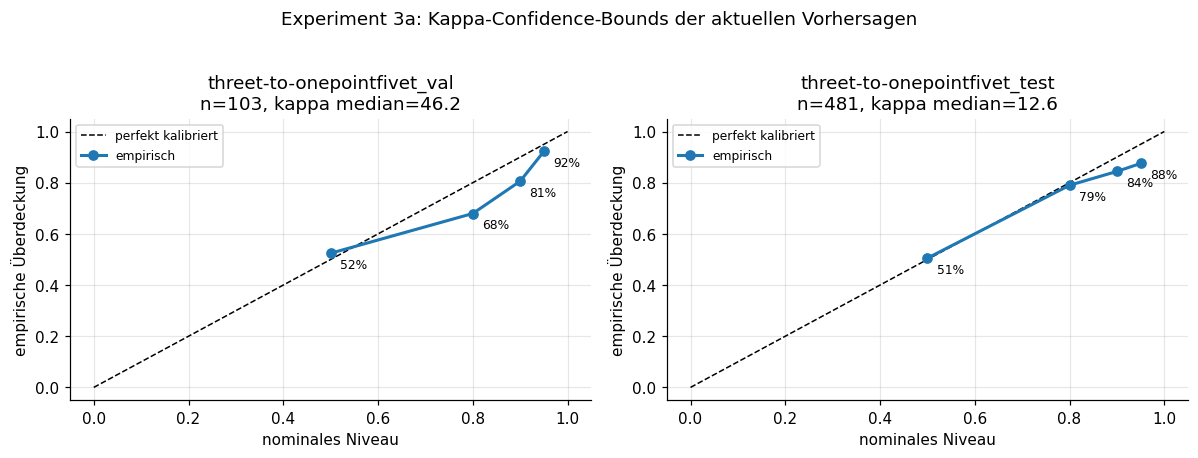

In [10]:
if bounds is not None:
    doms = list(bounds['evaluation'])
    fig, axes = plt.subplots(1, len(doms), figsize=(5.5 * len(doms), 4), squeeze=False)
    for ax, domain in zip(axes[0], doms):
        rep = bounds['evaluation'][domain]['bounds']
        levels = sorted(rep['levels'])
        emp = [rep['levels'][l]['empirical_coverage'] for l in levels]
        ax.plot([0, 1], [0, 1], 'k--', lw=1, label='perfekt kalibriert')
        ax.plot(levels, emp, 'o-', lw=2, label='empirisch')
        for l, e in zip(levels, emp):
            ax.annotate(f'{e:.0%}', (l, e), textcoords='offset points',
                        xytext=(6, -10), fontsize=8)
        ax.set_xlabel('nominales Niveau'); ax.set_ylabel('empirische Überdeckung')
        ax.set_title(f'{domain}\nn={rep["n"]}, kappa median={rep["kappa_median"]:.1f}')
        ax.legend(fontsize=8)
    fig.suptitle('Experiment 3a: Kappa-Confidence-Bounds der aktuellen Vorhersagen', y=1.03)
    plt.tight_layout(); plt.show()

### 3b: Unsicherheit simultan absenken

Pro Schritt **ein** kombiniertes Objective (kein alternierendes Schema):

$$\text{obj} = \underbrace{\hat\mu}_{\text{Ascent auf dem Dice}} \; - \; w \cdot \underbrace{\sqrt{\tfrac{\hat\mu(1-\hat\mu)}{\hat\kappa+1}}}_{\text{Descent auf der Unsicherheit}}$$

(Alternative `kappa_objective=log-kappa`: $\text{obj} = \hat\mu + w\log\hat\kappa$.)

Die interessante Frage ist nicht nur, ob der Dice besser wird, sondern was mit der
**Kalibrierung** passiert: sigma runterzudrücken ist trivial, ehrlich ist es nur, wenn die
Überdeckung dabei hält.

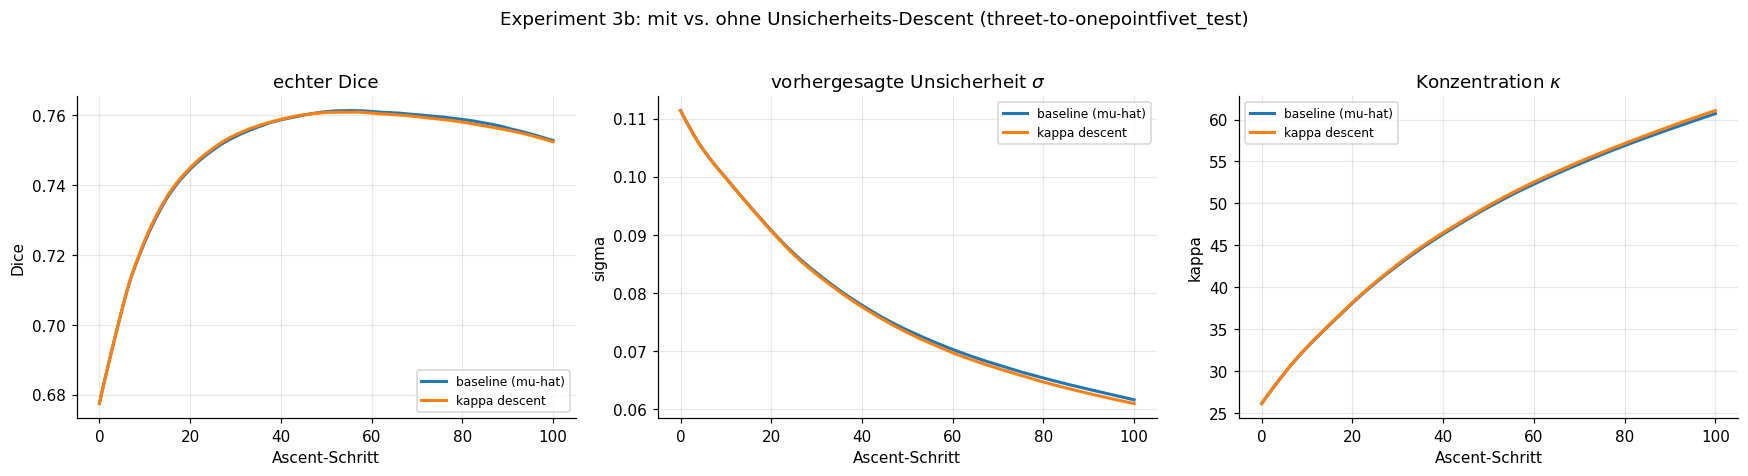

In [11]:
kcomp = {k: runs[k] for k in ('baseline (mu-hat)', 'kappa descent') if k in runs}

if len(kcomp) == 2:
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
    for label, payload in kcomp.items():
        axes[0].plot(step_curve(payload, TEST_DOMAIN, 'dice_per_step'), lw=2, label=label)
        axes[1].plot(step_curve(payload, TEST_DOMAIN, 'sigma_per_step'), lw=2, label=label)
        axes[2].plot(step_curve(payload, TEST_DOMAIN, 'kappa_per_step'), lw=2, label=label)
    axes[0].set_title('echter Dice'); axes[0].set_ylabel('Dice')
    axes[1].set_title(r'vorhergesagte Unsicherheit $\sigma$'); axes[1].set_ylabel('sigma')
    axes[2].set_title(r'Konzentration $\kappa$'); axes[2].set_ylabel('kappa')
    for ax in axes:
        ax.set_xlabel('Ascent-Schritt'); ax.legend(fontsize=8)
    fig.suptitle(f'Experiment 3b: mit vs. ohne Unsicherheits-Descent ({TEST_DOMAIN})', y=1.02)
    plt.tight_layout(); plt.show()

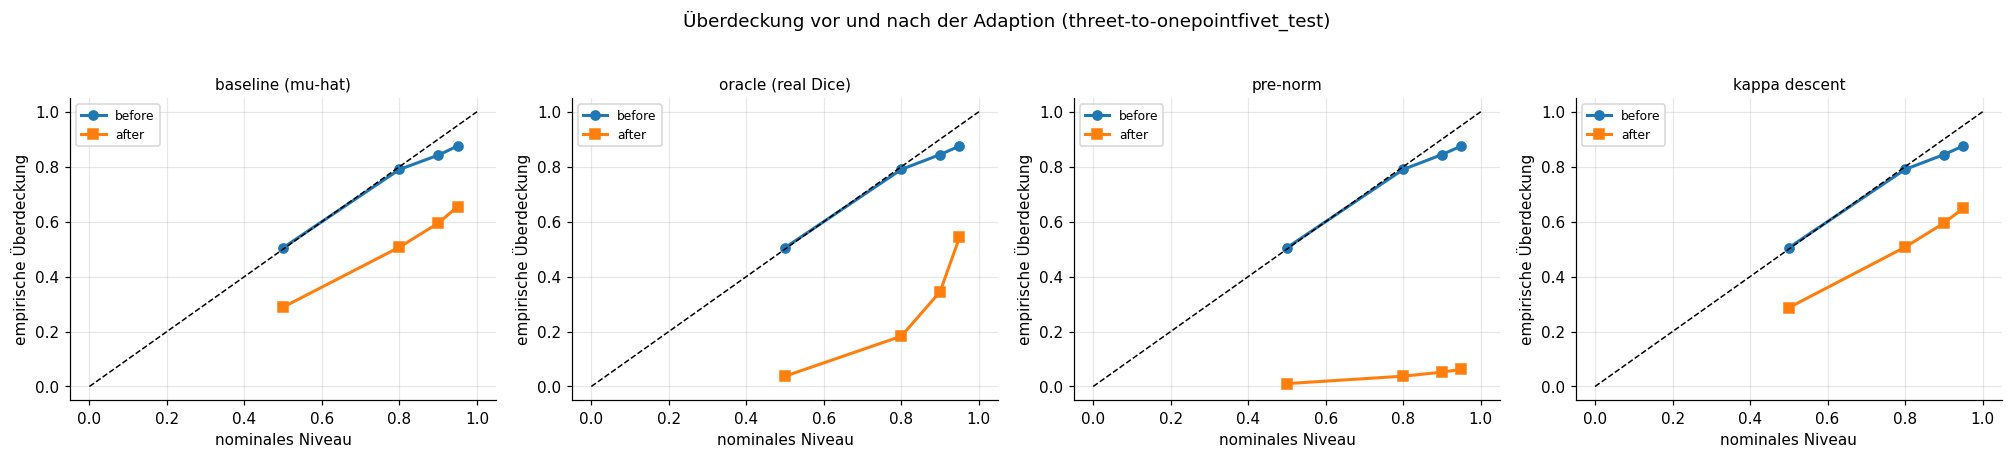

Lauf                    90% vorher  90% nachher  sigma vorher  sigma nachher
----------------------------------------------------------------------------
baseline (mu-hat)           84.2%        59.5%        0.1114         0.0615
oracle (real Dice)          84.4%        34.5%        0.1114         0.0976
pre-norm                    84.4%         5.2%        0.1114         0.0340
kappa descent               84.4%        59.5%        0.1114         0.0609


In [12]:
# Kalibrierung vor/nach der Adaption -- jeder TTA-Lauf speichert beides mit.
if runs:
    fig, axes = plt.subplots(1, len(runs), figsize=(4.6 * len(runs), 4), squeeze=False)
    for ax, (label, payload) in zip(axes[0], runs.items()):
        r = payload['evaluation'][TEST_DOMAIN]
        for key, style in (('bounds_before', 'o-'), ('bounds_after', 's-')):
            rep = r[key]
            levels = sorted(rep['levels'])
            emp = [rep['levels'][l]['empirical_coverage'] for l in levels]
            ax.plot(levels, emp, style, lw=2, label=key.replace('bounds_', ''))
        ax.plot([0, 1], [0, 1], 'k--', lw=1)
        ax.set_title(label, fontsize=10)
        ax.set_xlabel('nominales Niveau'); ax.set_ylabel('empirische Überdeckung')
        ax.legend(fontsize=8)
    fig.suptitle(f'Überdeckung vor und nach der Adaption ({TEST_DOMAIN})', y=1.03)
    plt.tight_layout(); plt.show()

    hdr = f'{"Lauf":22s} {"90% vorher":>11s} {"90% nachher":>12s} {"sigma vorher":>13s} {"sigma nachher":>14s}'
    print(hdr); print('-' * len(hdr))
    for label, payload in runs.items():
        r = payload['evaluation'][TEST_DOMAIN]
        b, a = r['bounds_before'], r['bounds_after']
        print(f'{label:22s} {b["levels"][0.9]["empirical_coverage"]:10.1%} '
              f'{a["levels"][0.9]["empirical_coverage"]:12.1%} '
              f'{b["sigma_mean"]:13.4f} {a["sigma_mean"]:14.4f}')

### 3c: Gewichts-Sweep — wie stark muss der Unsicherheits-Term sein?

Bei $w = 0.1$ auf $\sigma$ passiert praktisch nichts, und das hat einen Grund: der
mu-hat-Ascent treibt $\kappa$ ohnehin schon von 26 auf 61 hoch, der Zusatzterm ist dort
weitgehend redundant. Die Frage ist deshalb, ob ein *stärkerer* Term etwas anderes tut als
nur dieselbe Richtung zu verstärken. Verglichen werden:

* `ohne kappa-Term` — die Baseline ($w = 0$),
* `sigma  w=0.1` und `sigma  w=1.0` — Descent auf der Beta-Std,
* `log-kappa  w=0.01` und `log-kappa  w=0.1` — Ascent auf $\log\kappa$.

Die beiden Parametrisierungen sind **nicht** auf derselben Skala: $\sigma \approx 0.1$,
aber $\log\kappa \approx 3.3$, ein gleiches $w$ bedeutet also einen viel stärkeren
Term bei `log-kappa`. Deshalb die unterschiedlichen Gewichte.

Entscheidend ist nicht, ob $\sigma$ sinkt — das ist trivial erzwingbar —, sondern ob die
**Überdeckung** dabei hält. Eine schmalere Verteilung, die den echten Dice seltener
einschließt, ist keine bessere Unsicherheitsschätzung, sondern nur mehr Überkonfidenz.

In [13]:
def kappa_sweep():
    """Baseline + alle results/latent_tta_kappa_* Läufe, sortiert nach (Objective, w)."""
    out = {}
    base = runs.get('baseline (mu-hat)')
    if base is not None:
        out['ohne kappa-Term (w=0)'] = base
    entries = []
    for d in sorted(RESULTS.glob('latent_tta_kappa_*')):
        if not d.is_dir():
            continue
        payload = first_run(d.name)
        if payload is None:
            continue
        tta = payload['metadata']['tta']
        obj = str(tta.get('kappa_objective', 'sigma'))
        w = float(tta.get('kappa_weight', 0.0))
        entries.append((obj, w, f'{obj}  w={w:g}', payload))
    for _, _, label, payload in sorted(entries):
        out[label] = payload
    return out


sweep = kappa_sweep()
print(f'{len(sweep)} Läufe:', list(sweep))

5 Läufe: ['ohne kappa-Term (w=0)', 'log-kappa  w=0.01', 'log-kappa  w=0.1', 'sigma  w=0.1', 'sigma  w=1']


In [14]:
rows = []
for label, payload in sweep.items():
    r = payload['evaluation'][TEST_DOMAIN]
    d0 = r['dice_before'].mean().item(); d1 = r['dice_after'].mean().item()
    rows.append(dict(
        lauf=label,
        delta_dice=d1 - d0,
        dice_oracle_stop=r['best_dice'].mean().item(),
        mu_after=r['mu_after'].mean().item(),
        kappa_after=r['kappa_after'].mean().item(),
        sigma_after=r['sigma_after'].mean().item(),
        cov90_before=r['bounds_before']['levels'][0.9]['empirical_coverage'],
        cov90_after=r['bounds_after']['levels'][0.9]['empirical_coverage'],
        breite90_after=r['bounds_after']['levels'][0.9]['mean_width'],
    ))

try:
    import pandas as pd
    display(pd.DataFrame(rows).style.format({
        'delta_dice': '{:+.4f}', 'dice_oracle_stop': '{:.4f}', 'mu_after': '{:.4f}',
        'kappa_after': '{:.1f}', 'sigma_after': '{:.4f}',
        'cov90_before': '{:.1%}', 'cov90_after': '{:.1%}', 'breite90_after': '{:.4f}',
    }).hide(axis='index'))
except ImportError:
    for row in rows:
        print(row)

lauf,delta_dice,dice_oracle_stop,mu_after,kappa_after,sigma_after,cov90_before,cov90_after,breite90_after
ohne kappa-Term (w=0),+0.0754,0.7851,0.8425,60.7,0.0615,84.2%,59.5%,0.1951
log-kappa w=0.01,+0.0735,0.7848,0.8424,63.5,0.0607,84.2%,57.6%,0.1923
log-kappa w=0.1,+0.0656,0.7848,0.8369,68.5,0.0595,84.4%,52.6%,0.1889
sigma w=0.1,+0.0750,0.7840,0.8413,61.1,0.0609,84.4%,59.5%,0.1928
sigma w=1,+0.0546,0.7675,0.8146,62.5,0.0571,84.4%,56.5%,0.1752


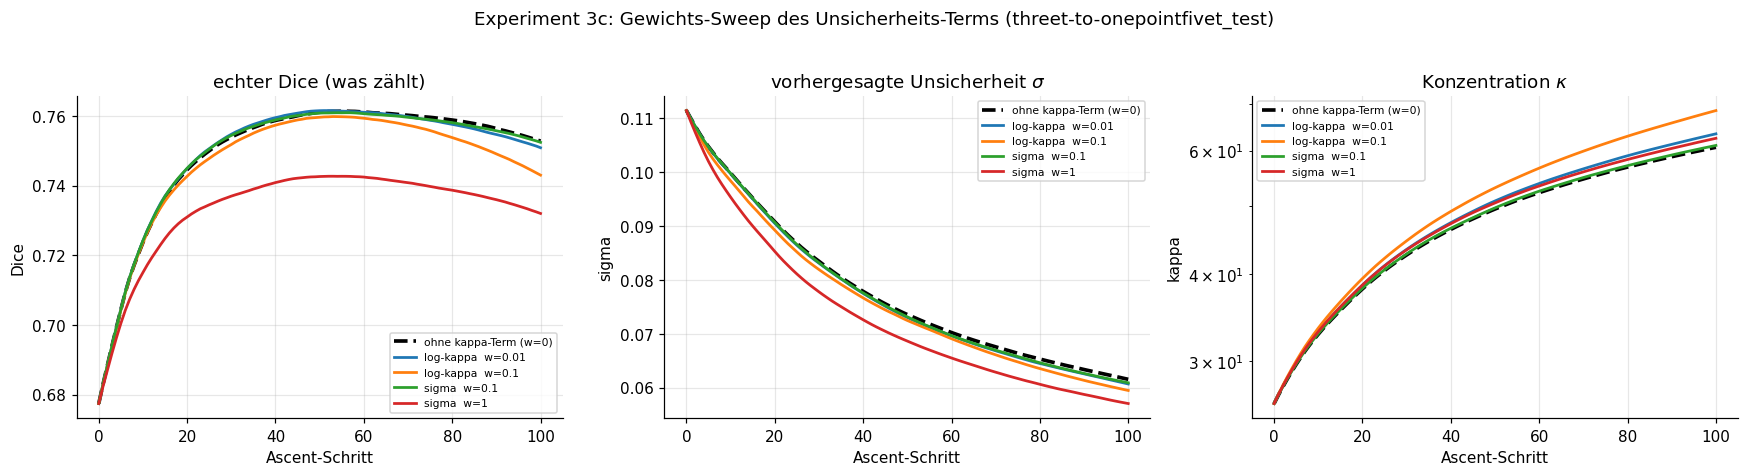

In [15]:
if len(sweep) > 1:
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
    for label, payload in sweep.items():
        kw = dict(lw=2.4, color='black', ls='--') if label.startswith('ohne') else dict(lw=1.8)
        axes[0].plot(step_curve(payload, TEST_DOMAIN, 'dice_per_step'), label=label, **kw)
        axes[1].plot(step_curve(payload, TEST_DOMAIN, 'sigma_per_step'), label=label, **kw)
        axes[2].plot(step_curve(payload, TEST_DOMAIN, 'kappa_per_step'), label=label, **kw)
    axes[0].set_title('echter Dice (was zählt)'); axes[0].set_ylabel('Dice')
    axes[1].set_title(r'vorhergesagte Unsicherheit $\sigma$'); axes[1].set_ylabel('sigma')
    axes[2].set_title(r'Konzentration $\kappa$'); axes[2].set_ylabel('kappa')
    axes[2].set_yscale('log')
    for ax in axes:
        ax.set_xlabel('Ascent-Schritt'); ax.legend(fontsize=7)
    fig.suptitle(f'Experiment 3c: Gewichts-Sweep des Unsicherheits-Terms ({TEST_DOMAIN})', y=1.02)
    plt.tight_layout(); plt.show()

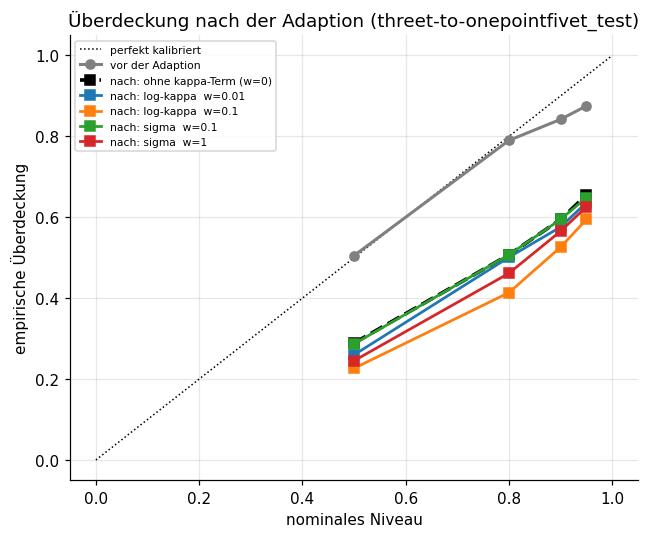

In [16]:
# Kalibrierung: nominal vs. empirisch NACH der Adaption, alle Sweep-Varianten
if len(sweep) > 1:
    fig, ax = plt.subplots(figsize=(6, 5))
    ref_rep = next(iter(sweep.values()))['evaluation'][TEST_DOMAIN]['bounds_before']
    lv = sorted(ref_rep['levels'])
    ax.plot([0, 1], [0, 1], 'k:', lw=1, label='perfekt kalibriert')
    ax.plot(lv, [ref_rep['levels'][l]['empirical_coverage'] for l in lv],
            'o-', color='grey', lw=2, label='vor der Adaption')
    for label, payload in sweep.items():
        rep = payload['evaluation'][TEST_DOMAIN]['bounds_after']
        style = (dict(lw=2.4, color='black', ls='--') if label.startswith('ohne')
                 else dict(lw=1.8, ls='-'))
        ax.plot(lv, [rep['levels'][l]['empirical_coverage'] for l in lv], marker='s',
                label=f'nach: {label}', **style)
    ax.set_xlabel('nominales Niveau'); ax.set_ylabel('empirische Überdeckung')
    ax.set_title(f'Überdeckung nach der Adaption ({TEST_DOMAIN})')
    ax.legend(fontsize=7)
    plt.tight_layout(); plt.show()

# Experiment 4 — Post-Norm-Head, Affine auch auf den Logits, Threshold-Orakel

Läufe aus `exp4_logit_affine.sh`: `latent_tta_postnorm` (Sites [0,17]) und
`latent_tta_postnorm_logits` (Sites [0,17] + Logits).

**Threshold-Orakel:** pro Bild *ein* globaler Logit-Threshold $t$ (`logits > t`), per
Grid-Search so gewählt, dass der echte harte Dice maximal wird (braucht Labels). Bei einem
1-Kanal-Netz ist die Logit-Affine auf der harten Maske exakt so eine Threshold-Verschiebung
($t = -\beta/\gamma$) — das Orakel ist also das Optimum dessen, was die Logit-Affine *allein*
an der Maske ändern kann. Was die TTA darüber hinaus erreicht, ist mehr als Rekalibrierung.

Die Plots werden vom Eval-Lauf auch als PNG nach `results/<run>/<ckpt>/plots/` geschrieben.
Overlay: grün = TP, rot = FP, blau = FN.


In [ ]:
from apps.plot_latent_tta import plot_example, plot_domain_summary

EXP4 = {
    'post-norm, sites [0,17]':          'latent_tta_postnorm',
    'post-norm, sites [0,17] + logits': 'latent_tta_postnorm_logits',
}
runs4 = {label: first_run(d) for label, d in EXP4.items()}
runs4 = {k: v for k, v in runs4.items() if v is not None}

for label, payload in runs4.items():
    ev = payload['evaluation'][TEST_DOMAIN]
    print(f"{label:34s} Dice {ev['dice_before'].mean():.4f} -> {ev['dice_after'].mean():.4f} | "
          f"best step {ev['best_dice'].mean():.4f} | threshold oracle {ev['thr_oracle_dice'].mean():.4f}"
          + (f" | domain threshold {ev['thr_global_dice'].mean():.4f}" if ev.get('thr_global_dice') is not None else ''))


In [ ]:
for label, payload in runs4.items():
    fig = plot_domain_summary(payload['evaluation'][TEST_DOMAIN], f'{label} | {TEST_DOMAIN}')
    plt.show()


### Einzelne Beispiele: predicted vs. actual Dice, kappa, Masken

`EXAMPLE_RUN` wählt den Lauf, `k` läuft über die gespeicherten Beispiele (`tta.n_examples`).

In [ ]:
EXAMPLE_RUN = 'post-norm, sites [0,17] + logits'
if EXAMPLE_RUN in runs4:
    ev = runs4[EXAMPLE_RUN]['evaluation'][TEST_DOMAIN]
    for k in range(len(ev['examples']['index'])):
        plot_example(ev, k, f'{EXAMPLE_RUN} | {TEST_DOMAIN}')
        plt.show()


## Was in den Pickles steht

`results/<experiment>/<checkpoint>/latent_tta.pkl`:

* `metadata` — vollständige `data`/`unet`/`model`/`tta`-Configs und beide Checkpoint-Pfade,
  d.h. jeder Lauf ist aus seiner Datei heraus reproduzierbar.
* `evaluation[<domain>]` — pro Bild `dice_before/after`, `mu_*`, `kappa_*`, `sigma_*`,
  `logit_drift`; pro Bild **und Schritt** die Matrizen `[N, S]`: `dice_per_step`,
  `mu_per_step`, `kappa_per_step`, `sigma_per_step`, `logit_drift_per_step`,
  `soft_dice_per_step`; dazu `best_step`/`best_dice` (Orakel-Stopp), die
  Batch-Traces und `bounds_before`/`bounds_after`.

`results/kappa_bounds/<checkpoint>/kappa_bounds.pkl`: pro Domäne `dice`, `mu`, `kappa` und
der `bounds`-Report (Überdeckung, Breite, PIT, Korrelationen).